In [1]:
# === Google Colab 自動環境セットアップ ===
# 本セルを実行すると、Google Colab 上で必要なリポジトリのクローン、
# 依存ライブラリのインストール、および共通シミュレーションモジュールの準備が自動的に行われます。
import os
import sys
import subprocess

if 'google.colab' in str(get_ipython()):
    print('Google Colab 環境を検出しました。環境をセットアップします...')
    repo_name = 'study-mikanos'
    if not os.path.exists(repo_name):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
    os.chdir(repo_name)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', '.'], check=True)
    print('Colab 環境のセットアップが完了しました！')
else:
    # ローカル環境のパス設定 (study-mikanos を最優先でロード)
    repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '5' else os.getcwd()
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print('ローカル環境で実行中です。ルートディレクトリ:', repo_root)

ローカル環境で実行中です。ルートディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 5.5 コンソールクラス (`Implementing Console Class`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/5/5.5_Implementing_Console_Class.ipynb)

前節（5.4節 `osbook_day05d`）では、終端ヌル文字 (`'\0'`) を検出して文字を横方向に連続描画する `WriteString()` と、Newlib C標準ライブラリ（`sprintf`）の統合を実現しました。これにより、任意の文字列や数値をフォーマットしてピクセル画面に表示できるようになりました。

しかし、前節までの描画方法には**実用的なOS開発において極めて不便な課題**が残されていました：
- 出力するたびに、呼び出し側が毎回 `(x, y)` 座標（ピクセル単位）を自前で計算・指定しなければならない。
- 画面の右端や下端に到達しても**自動改行やスクロールが行われない**ため、行数が増えると文字が画面外にはみ出して消滅するか、画面最下部で文字が重なって判読不能になる。

本節（`osbook_day05e`）では、これらの課題を一挙に解決し、PC/AT互換機の伝統的テキストモード（80列×25行）をエミュレートする **`Console` クラス** を設計・実装します。

---

### 🎯 本節の主要学習目標
1. **コンソールクラスの責務と抽象化**:
   - 画面ピクセル座標 (`x, y`) を隠蔽し、**「行（Row: 0〜24）」** と **「列（Column: 0〜79）」** のキャラクタ座標系を提供。
   - 文字出力ごとのカーソル自動前進、改行コード (`'\n'`) の自動処理。
2. **25行×80列 テキストバッファ (`buffer_[25][81]`) の二重管理モデル**:
   - なぜ画面（VRAM）の直接読み戻しを避け、カーネルメモリ上の配列に文字コードをキャッシュするのか？
   - MMIO（Memory-Mapped I/O）のバスウェイト（Read Penalty）とフォント逆変換不可能性のアーキテクチャ的解説。
3. **1行スクロールアルゴリズムの完全解明**:
   - 最下行あふれ時の4段階シーケンス（VRAM全消去 → `memcpy` 行シフト → `WriteString` 再描画 → 最下行クリア）。
4. **Newlib `sbrk()` スタブの POSIX 準拠改善**:
   - `day05d` の `return NULL;` から、POSIX規格準拠の `errno = ENOMEM; return (caddr_t)-1;` への進化。
5. **C++20 & Python による 27行出力実験の完全実証**:
   - `line 0` から `line 26`（計27行）を出力したときのスクロール挙動（`line 0`〜`line 2` の3行が押し出され、画面最上部が `line 3`、最下部が `line 26` となる様子）の完全検証。

## 1. なぜコンソールクラスが必要なのか？（動機と課題）

### 1.1 座標直接指定描画の限界
前節（5.4節）における `KernelMain` の出力コードを振り返ってみましょう：

```cpp
WriteString(*pixel_writer, 0, 66, "Hello, world!", {0, 0, 255});

char buf[128];
sprintf(buf, "1 + 2 = %d", 1 + 2);
WriteString(*pixel_writer, 0, 82, buf, {0, 0, 0});
```

この方法には以下の3大欠点があります：
1. **呼出側の負荷**: 文字列を表示したいだけなのに、プログラマが「フォント高さ 16 ピクセルだから次は $66 + 16 = 82$ だな」と毎回ピクセル計算しなければならない。
2. **改行コード (`\n`) の非対応**: `WriteString` は `'\n'` を制御文字として解釈せず、単なる未定義文字として描画（または無視）してしまう。
3. **行あふれ（Overflow）時の破綻**: 画面の高さ（400pxや768px）を超えて出力し続けると、画面外の未割り当てメモリ領域を破壊するか、最下部に重なって読めなくなる。

```mermaid
flowchart TD
    subgraph Bad ["前節までの方式: 呼出側が座標を毎回指定"]
        A["呼出元 (KernelMain)"] -->|"x=0, y=66 を直接指定"| B["WriteString()"]
        A -->|"x=0, y=82 を自前計算して指定"| B
        A -->|"画面最下行を超えると破綻！"| FAIL["画面外への書き込み / 文字重なり"]
    end
    subgraph Good ["本節の方式: Console クラスによるカプセル化"]
        C["呼出元 (KernelMain)"] -->|"console.PutString(\"line 1\\n\")"| D["Console クラス"]
        D -->|"カーソル自動前進 (col++)"| E["VRAM 描画"]
        D -->|"改行コード検知 (\n)"| F["行頭復帰 & 改行 (row++)"]
        D -->|"最下行あふれ検知"| G["自動1行スクロール & 再描画"]
    end
```

### 1.2 端末（Console）の標準規格: 80列×25行
IBM PC および PC/AT 互換機の時代から、コンピュータのテキスト端末モード（VGAテキストモード）では **「80文字 × 25行」** がデファクトスタンダードとして使われてきました。
MikanOS もこの伝統に従い、コンソールサイズを以下のように定めます：

$$	ext{コンソール列数 } kColumns = 80,\quad 	ext{コンソール行数 } kRows = 25$$

フォントサイズは 1文字あたり 横 8 ピクセル × 縦 16 ピクセルであるため、コンソール全体のピクセル専有領域は以下のようになります：

$$	ext{コンソール領域の幅 } W = 8 	imes 80 = 640 	ext{ [pixels]}$$
$$	ext{コンソール領域の高さ } H = 16 	imes 25 = 400 	ext{ [pixels]}$$

カーソルが現在指しているキャラクタ座標を $(	ext{cursor\_column\_}, 	ext{cursor\_row\_})$ とすると、画面上のピクセル左上座標 $(X, Y)$ は以下の単純な一次式で求まります：

$$egin{cases}
X = 8 	imes 	ext{cursor\_column\_} & (0 \le 	ext{cursor\_column\_} < 80) \
Y = 16 	imes 	ext{cursor\_row\_} & (0 \le 	ext{cursor\_row\_} < 25)
\end{cases}$$

## 2. コンソールクラスの内部設計とデータ構造

### 2.1 クラス定義 (`kernel/console.hpp`)
MikanOS の `Console` クラスのヘッダ定義（`osbook_day05e`）を確認します：

```cpp
#pragma once

#include "graphics.hpp"

class Console {
 public:
  static const int kRows = 25, kColumns = 80;

  Console(PixelWriter& writer,
      const PixelColor& fg_color, const PixelColor& bg_color);
  void PutString(const char* s);

 private:
  void Newline();

  PixelWriter& writer_;
  const PixelColor fg_color_, bg_color_;
  char buffer_[kRows][kColumns + 1];
  int cursor_row_, cursor_column_;
};
```

各メンバ変数の役割は以下の通りです：
- `writer_`: 画面へピクセルを描画するための `PixelWriter` への参照。
- `fg_color_`: 文字の前景色（描画色、デフォルトは黒 `{0, 0, 0}`）。
- `bg_color_`: 文字の背景色（画面消去色、デフォルトは白 `{255, 255, 255}`）。
- `buffer_[kRows][kColumns + 1]`: 25行×81列の文字配列。
- `cursor_row_`, `cursor_column_`: 現在のカーソル位置（0-indexed）。

### 2.2 なぜカーネルメモリ上に文字バッファ配列が必要なのか？
ここで最大のアーキテクチャ的疑問が生じます：
> **「画面のスクロールなら、VRAM上のピクセル矩形をまるごと上に16ピクセル分コピー（ビットブリット: BitBlt）すれば、文字バッファ配列など不要なのではないか？」**

これには低レイヤハードウェアおよびシステム設計上の **2つの決定的な理由** があります：

1. **VRAM (MMIO) の読み出しペナルティ (Read Penalty)**:
   - フレームバッファのアドレスはグラフィックスカードのビデオメモリ（VRAM）にマッピングされており、CPU から見ると Memory-Mapped I/O (MMIO) 領域です。
   - MMIO への書き込み（Write）はライトバッファ等により比較的高速に行えますが、**MMIO からの読み出し（Read）は CPU キャッシュが無効化されているため、PCIe バスの往復レイテンシが直撃し、主メモリ（DRAM）に比べて数十倍〜数百倍低速** です。
   - $640 	imes 400 	imes 4 = 1	ext{ MB}$ もの VRAM を読み戻して再度書き込むと、画面スクロールのたびに著しいチラつきとフリーズが発生します。
2. **ピクセル情報から文字コードを逆変換することの不可能性**:
   - 一度ピクセルとしてレンダリングされてしまうと、それは単なる色データの集合であり、「どの文字（ASCIIコード）だったか」という情報は失われます。
   - 将来的にテキストのコピー＆ペースト、画面の再描画、端末エミュレーション（VT100互換）、リダイレクトを実装するためには、**「文字コードそのもの」** を保持している必要があります。

### 2.3 `kColumns + 1` (81バイト) の設計意図
配列の列数が 80 ではなく `80 + 1 = 81` になっている理由は、C言語の文字列終端ルールにあります。
`WriteString(writer_, 0, 16 * row, buffer_[row], fg_color_)` は、末尾の `' '` を見つけるまで描画を続けます。
もし 80 行ぴったりしかメモリを確保していないと、80文字すべてが文字で埋まった際にヌル文字を置く場所がなくなり、次の行のメモリ領域まで `WriteString` が暴走してしまいます。
`kColumns + 1` とすることで、**80文字のテキストの末尾に必ず安全に `' '` を配置できる** のです。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:20226: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


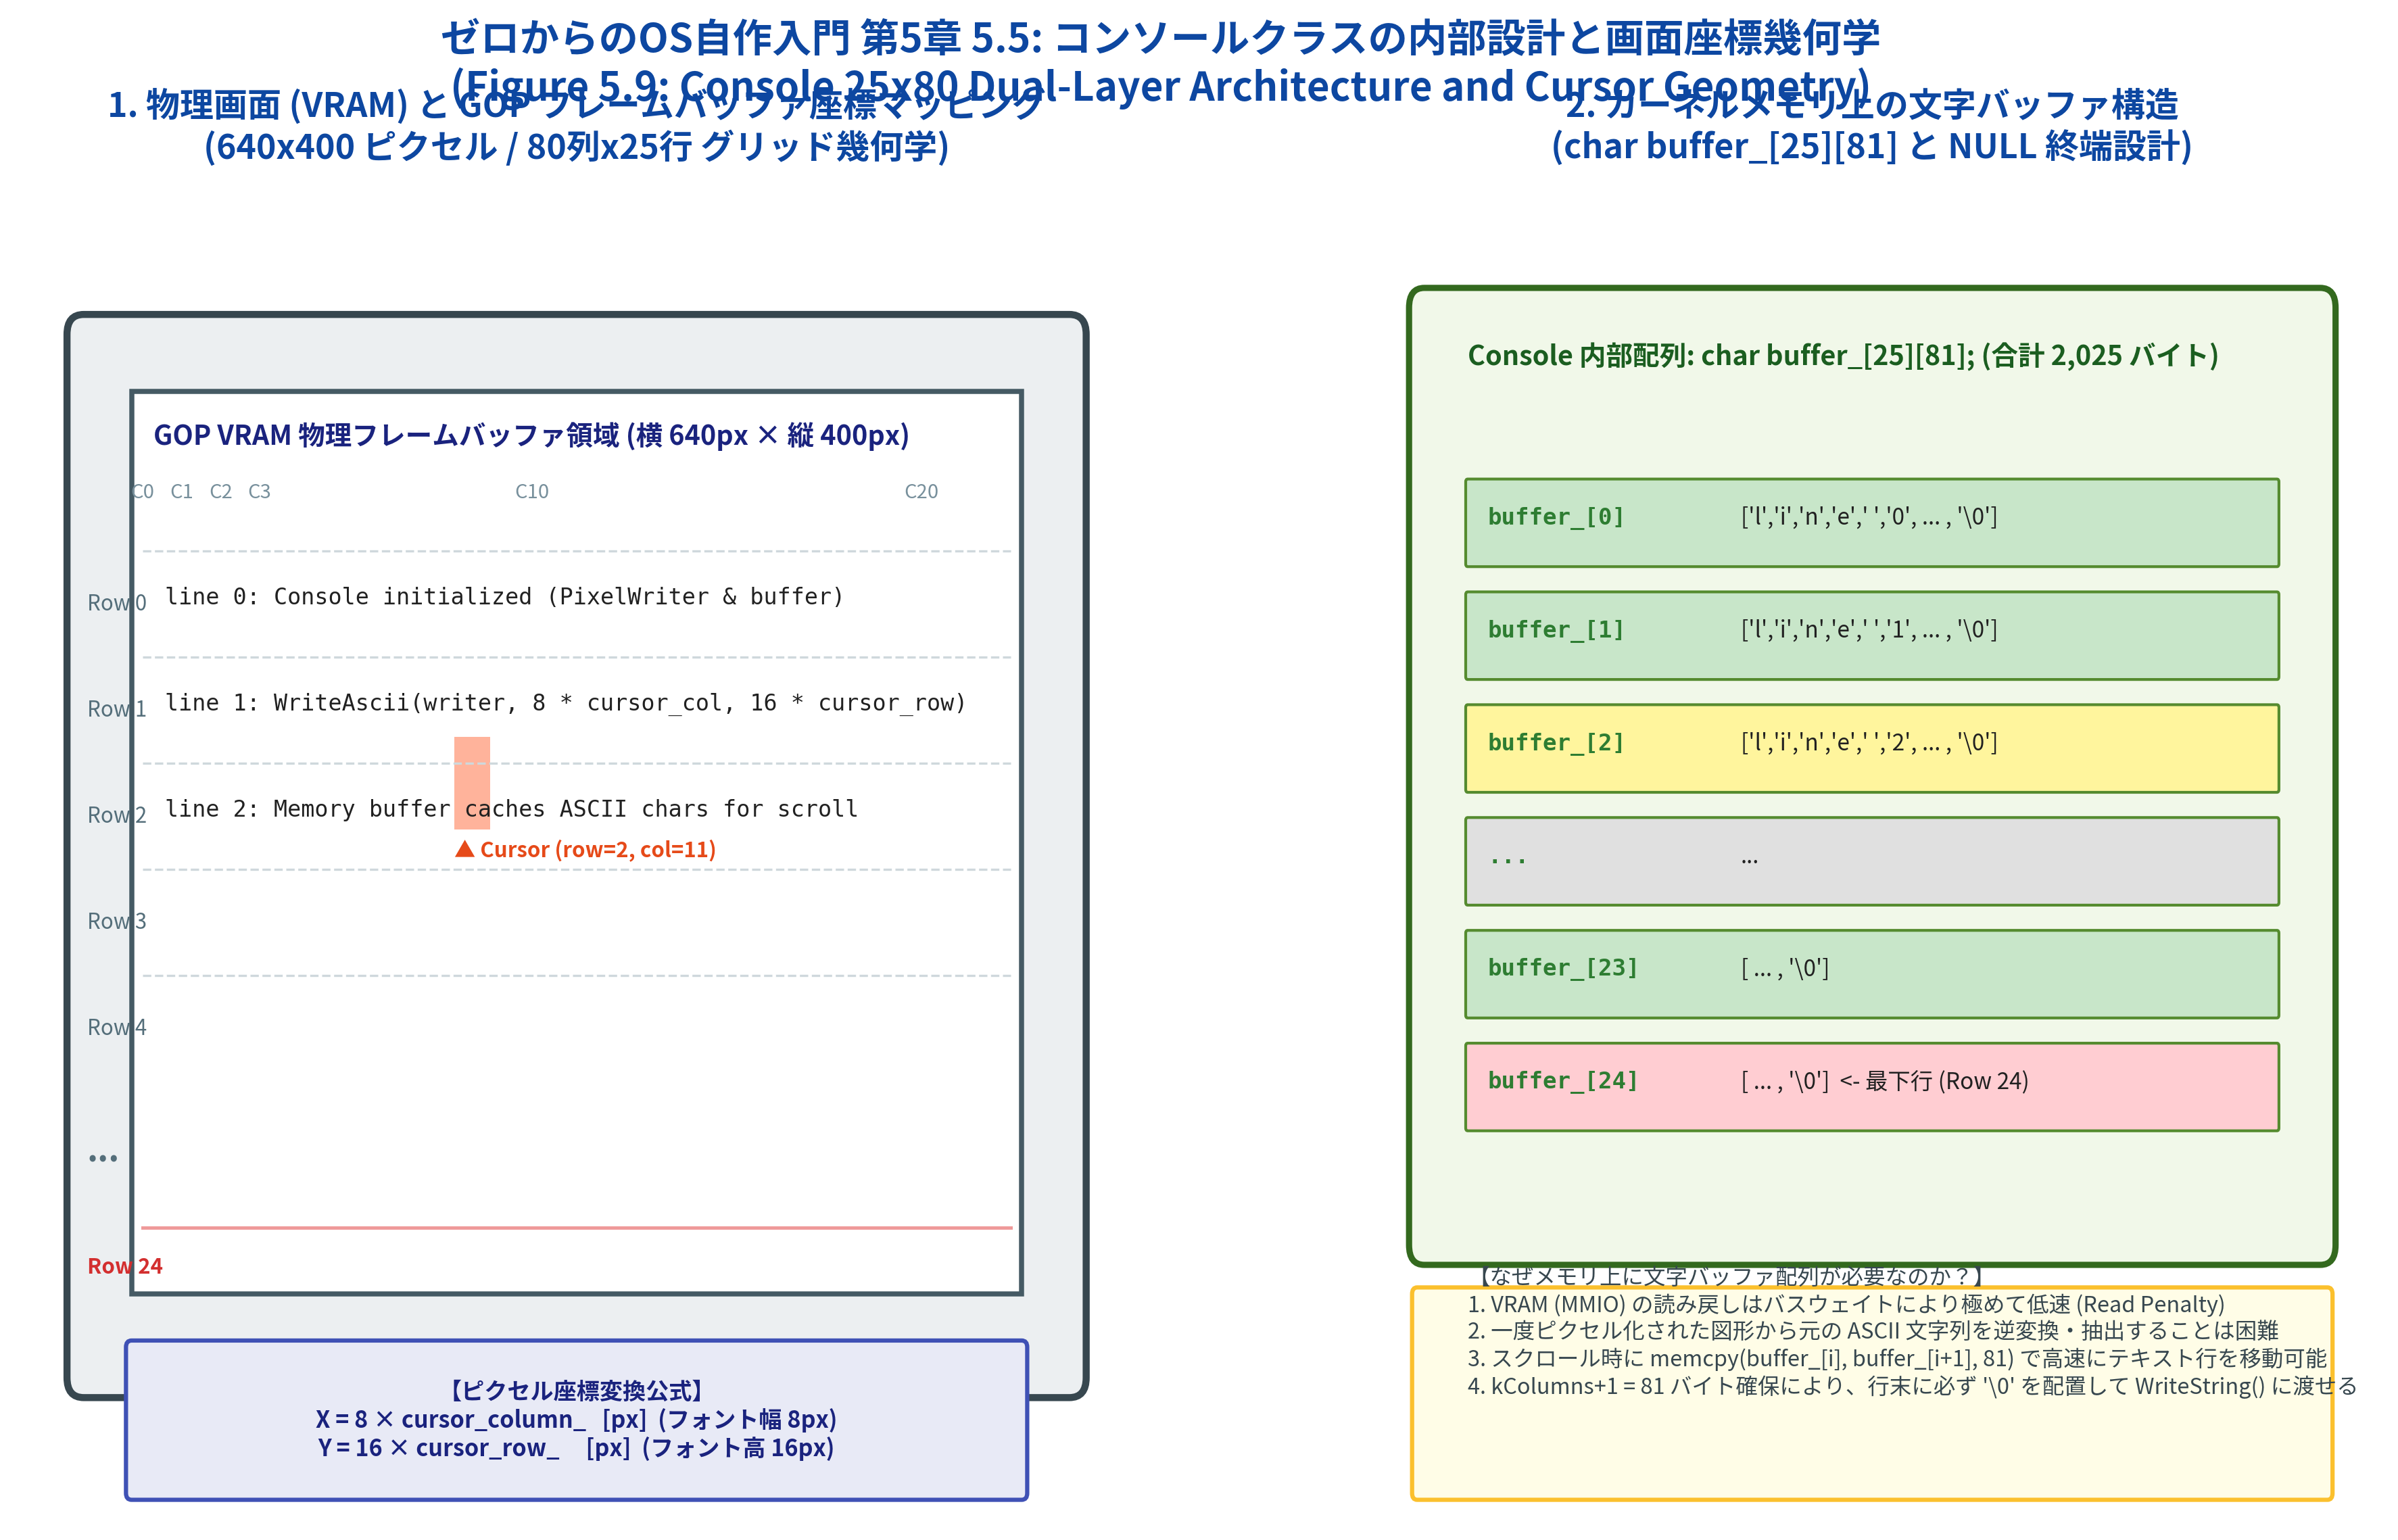

In [2]:
# Figure 5.9: コンソールクラスの二重管理モデルとカーソル幾何学の可視化
from common import plot_fig5_09_console_buffer_and_cursor_model
from IPython.display import Image, display

fig9_path = plot_fig5_09_console_buffer_and_cursor_model("5/result/fig5_09_console_buffer_and_cursor_model.png")
display(Image(filename=fig9_path))

## 3. 文字列出力 `PutString()` とカーソル進行制御

### 3.1 `PutString()` の実装コード
`kernel/console.cpp` における `PutString()` の実装を確認します：

```cpp
void Console::PutString(const char* s) {
  while (*s) {
    if (*s == '
') {
      Newline();
    } else if (cursor_column_ < kColumns - 1) {
      WriteAscii(writer_, 8 * cursor_column_, 16 * cursor_row_, *s, fg_color_);
      buffer_[cursor_row_][cursor_column_] = *s;
      ++cursor_column_;
    }
    ++s;
  }
}
```

### 3.2 処理フローの詳細解説
1. `while (*s)`:
   - 引数として渡されたC文字列のポインタ `s` を 1 文字ずつ先頭から走査します。終端ヌル文字 (`' ' = 0`) に達したらループを抜けます。
2. `if (*s == '
')`:
   - 現在の文字が改行文字 (`'
' = 0x0A`) であれば、プライベートメソッド `Newline()` を呼び出し、行頭復帰と改行（必要ならスクロール）を行います。
3. `else if (cursor_column_ < kColumns - 1)`:
   - 通常文字の場合、現在のカーソル列が `kColumns - 1`（つまり $80 - 1 = 79$ 列目）未満であるかを判定します。
   - 79列目未満であれば：
     - `WriteAscii(writer_, 8 * cursor_column_, 16 * cursor_row_, *s, fg_color_)`: ピクセル画面にフォントを展開して描画します。
     - `buffer_[cursor_row_][cursor_column_] = *s`: カーネルメモリの文字バッファに文字コードを記録します。
     - `++cursor_column_`: カーソルを右に1文字分（8ピクセル分）進めます。
   - **境界保護（Boundary Protection）**: もし1行に80文字以上の長い文字列が改行なしで送られてきた場合、この `else if` の条件により 79文字目以降の文字は無視（破棄）されます。これにより、配列 `buffer_` の境界外書き込み（Buffer Overflow）を確実に防止しています。

## 4. 改行 `Newline()` とスクロールアルゴリズム

### 4.1 `Newline()` の実装コード
コンソールの中核アルゴリズムである `Newline()` の実装を確認します：

```cpp
void Console::Newline() {
  cursor_column_ = 0;
  if (cursor_row_ < kRows - 1) {
    ++cursor_row_;
  } else {
    for (int y = 0; y < 16 * kRows; ++y) {
      for (int x = 0; x < 8 * kColumns; ++x) {
        writer_.Write(x, y, bg_color_);
      }
    }
    for (int row = 0; row < kRows - 1; ++row) {
      memcpy(buffer_[row], buffer_[row + 1], kColumns + 1);
      WriteString(writer_, 0, 16 * row, buffer_[row], fg_color_);
    }
    memset(buffer_[kRows - 1], 0, kColumns + 1);
  }
}
```

### 4.2 スクロールシーケンスの4段階ステップ
カーソルが行 0 〜 23 にある間は、`cursor_column_ = 0; ++cursor_row_;` だけで瞬時に改行できます。
しかし、カーソルが**最下行（`cursor_row_ == 24`）にある状態で改行が発生した瞬間**、以下の4段階スクロールシーケンスが発火します：

```mermaid
sequenceDiagram
    autonumber
    participant App as Kernel / アプリ
    participant Con as Console
    participant Buf as メモリバッファ (buffer_)
    participant VRAM as フレームバッファ (VRAM)

    App->>Con: PutString("
")
    Con->>Con: cursor_column_ = 0
    Note over Con: cursor_row_ == 24 (最下行！)
    Con->>VRAM: 【Step 1】640x400 ピクセルを bg_color_ (白) で塗りつぶし
    loop row = 0 to 23
        Con->>Buf: 【Step 2】memcpy(row, row+1, 81) [行を1行上にシフト]
        Con->>VRAM: 【Step 3】WriteString(0, 16*row, buffer_[row]) [シフト後の行を再描画]
    end
    Con->>Buf: 【Step 4】memset(row=24, 0, 81) [最下行バッファをゼロクリア]
    Note over Con: cursor_row_ = 24 を維持
```

- **Step 1: VRAM コンソール領域の全面消去**:
  - $0 \le x < 640$, $0 \le y < 400$ の全ピクセル（計 256,000 ピクセル）を `bg_color_`（白）で塗りつぶします。これにより、画面上の古い文字ピクセルが完全に一掃されます。
- **Step 2: メモリバッファの行シフト (`memcpy`)**:
  - `memcpy(buffer_[row], buffer_[row + 1], kColumns + 1)` により、1行下の文字配列（81バイト）を1行上にコピーします。
  - 行 0 には旧行 1 の内容が、行 1 には旧行 2 の内容が上書きされ、最も古かった旧行 0 の文字列はここで破棄されます。
- **Step 3: VRAM への再描画 (`WriteString`)**:
  - コピーしたばかりの `buffer_[row]` を、新しい行座標 $Y = 16 	imes row$ に `WriteString` で描画します。
- **Step 4: 最下行のクリア (`memset`)**:
  - 新しく空いた最下行 `buffer_[kRows - 1]` をゼロクリア (`memset`) します。
  - カーソル位置 `cursor_row_` は最下行 `kRows - 1`（= 24）のまま維持され、次の文字入力を待機します。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:20367: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


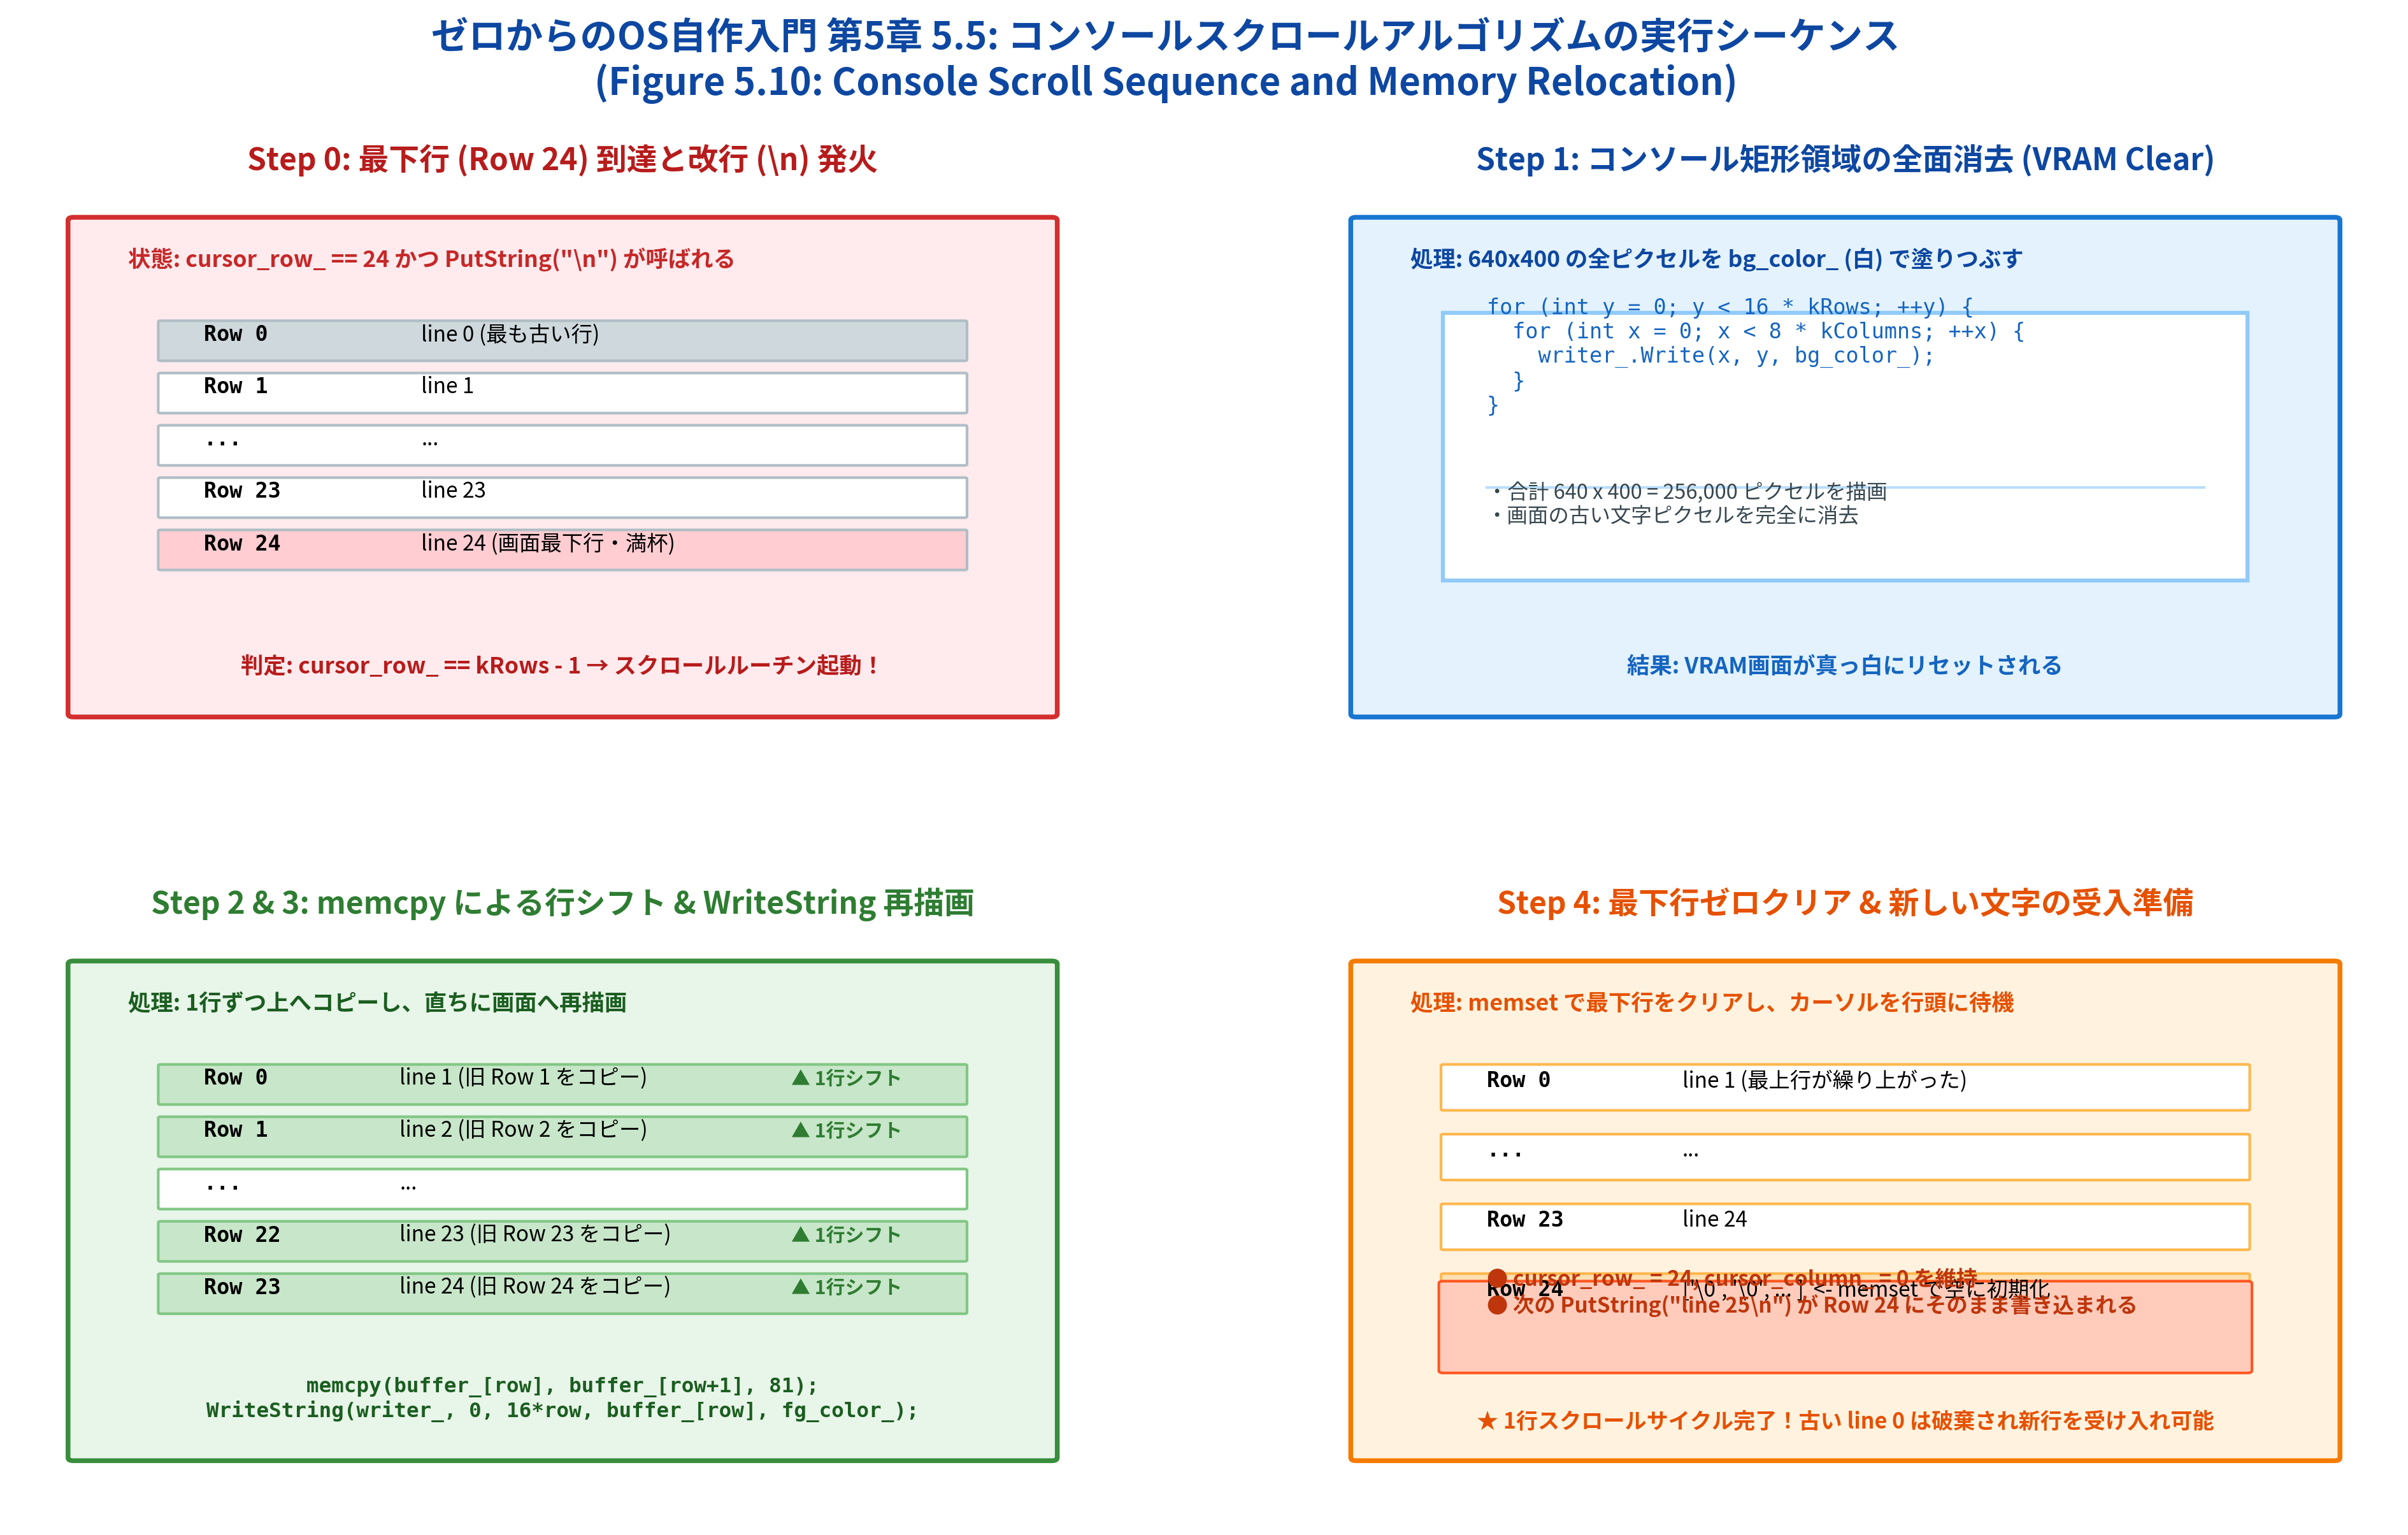

In [3]:
# Figure 5.10: コンソールスクロールアルゴリズムの実行シーケンスの可視化
from common import plot_fig5_10_console_scroll_sequence
from IPython.display import Image, display

fig10_path = plot_fig5_10_console_scroll_sequence("5/result/fig5_10_console_scroll_sequence.png")
display(Image(filename=fig10_path))

## 5. Newlib `sbrk()` スタブの POSIX 準拠改善

### 5.1 `day05d` と `day05e` の差分
前節（5.4節 `day05d`）で追加した Newlib システムコールスタブ `kernel/newlib_support.c` では、以下のように仮実装していました：

```c
// day05d
caddr_t sbrk(int incr) {
  return NULL;
}
```

しかし、`day05e` ではこれが以下のように改善されました：

```c
// day05e
#include <errno.h>
#include <sys/types.h>

caddr_t sbrk(int incr) {
  errno = ENOMEM;
  return (caddr_t)-1;
}
```

### 5.2 なぜ `(caddr_t)-1` と `errno = ENOMEM` なのか？
UNIX / POSIX 標準仕様において、`sbrk(2)` システムコールの仕様は以下のように明確に規定されています：

> **POSIX.1-2001 仕様抜粋**:
> - 成功時: 割り当て前の古いプログラムブレーク（ヒープ境界アドレス）を返す。
> - 失敗時: `(void *)-1`（または `(caddr_t)-1`）を返し、エラーコードとして `errno` に `ENOMEM` (*Cannot allocate memory*) を設定する。

もし `sbrk()` が失敗時に `NULL` (`0`) を返すと、ライブラリ側（Newlib の `malloc` 等）は **「仮想アドレス 0番地へのヒープ拡張に成功した」** と誤認してしまい、NULL ポインタ付近のメモリを破壊する致命的なバグに繋がります。
したがって、`errno = ENOMEM; return (caddr_t)-1;` を返すことが標準規格に準拠した正しい失敗通知となります。

## 6. 対話型 C++20 コンパイル & 27行出力実験の完全検証

書籍の `main.cpp`（`day05e`）では、コンソールが正常にスクロールするかどうかを検証するために、以下のテストコードを実行しています：

```cpp
Console console{*pixel_writer, {0, 0, 0}, {255, 255, 255}};

char buf[128];
for (int i = 0; i < 27; ++i) {
  sprintf(buf, "line %d
", i);
  console.PutString(buf);
}
```

このコードを実行したとき、内部で何が起きるかをステップ・バイ・ステップで追跡しましょう：
1. `i = 0` 〜 `23`: 計24行が出力され、カーソルは最下行（Row 24, Col 0）に到達。スクロール回数はまだ 0 回。
2. `i = 24`（25行目）: Row 24 に `"line 24"` が書かれ、末尾の `'
'` で **第1回スクロール** が発火！
   - `line 0` が画面外へ押し出され、Row 0 は `"line 1"`、Row 23 は `"line 24"` になる。
3. `i = 25`（26行目）: Row 24 に `"line 25"` が書かれ、末尾の `'
'` で **第2回スクロール** が発火！
   - `line 1` が画面外へ押し出され、Row 0 は `"line 2"`、Row 23 は `"line 25"` になる。
4. `i = 26`（27行目）: Row 24 に `"line 26"` が書かれ、末尾の `'
'` で **第3回スクロール** が発火！
   - `line 2` が画面外へ押し出され、Row 0 は `"line 3"`、Row 23 は `"line 26"` になる。

以下のセルで、ホスト C++20 コードをコンパイルし、この挙動を厳密にアサーション検証します。

In [4]:
# C++20 スタンドアロンシミュレータのコンパイルと実行
import subprocess
import json

cpp_src = "src/ch05/console_sim.cpp"
cpp_bin = "src/ch05/console_sim"

# 1. コンパイル
compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_src, "-o", cpp_bin]
print(f"コンパイルコマンド実行: {' '.join(compile_cmd)}")
subprocess.run(compile_cmd, check=True)
print("コンパイル成功！\n")

# 2. 実行 & JSON 検証
run_cmd = [cpp_bin, "--json"]
result = subprocess.run(run_cmd, capture_output=True, text=True, check=True)
print(result.stdout)

コンパイルコマンド実行: g++ -std=c++20 -O2 -Wall -Wextra src/ch05/console_sim.cpp -o src/ch05/console_sim


コンパイル成功！

 MikanOS Chapter 5.5: Console Class & Scroll Simulation (osbook_day05e)

[Step 1] Initial state check:
  -> Initial cursor (row=0, col=0), scroll_count=0 verified.

[Step 2] Printing 24 lines (line 0 .. line 23)...
  -> 24 lines printed. Cursor reached bottom row 24 without scrolling.
     Top row [0]:  "line 0"
     Row [23]:     "line 23"
     cursor_row: 24, scroll_count: 0

[Step 3] Printing line 24 (25th line, triggers 1st scroll upon '\n')...
  -> 1st scroll occurred successfully:
     Top row [0] shifted to: "line 1" (line 0 scrolled out)
     Row [23] is now:        "line 24"
     scroll_count: 1

[Step 4] Printing line 25 (26th line, triggers 2nd scroll)...
  -> 2nd scroll verified: Top row [0] is "line 2"

[Step 5] Printing line 26 (27th line, completes loop of day05e main.cpp)...
  -> 3rd scroll verified: Top row [0] is "line 3", Row [23] is "line 26"

[Step 6] Testing column limit clipping (80 columns)...
  -> Column properly clipped at 79 chars (kColumns - 1 = 79

## 7. Python (`ConsoleSim`) によるフレームバッファ描画シミュレーション

次に、共通モジュール `common/os_sim.py` の `ConsoleSim` クラスを用いて、MikanOS のコンソール描画と画面スクロールを Python 上で完全に再現します。
27行出力後の VRAM フレームバッファ（$640 	imes 400$ ピクセル）の状態をプロットし、文字配置とスクロール結果を視覚的に確認します。

In [5]:
# Python ConsoleSim による 27行出力シミュレーションと状態確認
from common import ConsoleSim

console = ConsoleSim()

# 27行出力ループ (osbook_day05e と完全同一)
for i in range(27):
    console.put_string(f"line {i}\n")

print(f"■ スクロール発生回数: {console.scroll_count} 回")
print(f"■ 最終カーソル位置: row={console.cursor_row}, col={console.cursor_column}")
print(f"■ スクロールアウトした行の履歴: {console.scroll_history}")
print(f"■ 画面最上行 (Row 0):  '{console.get_line(0)}'")
print(f"■ 画面最下行付近 (Row 23): '{console.get_line(23)}'")
print(f"■ 最下行 (Row 24, 次の入力待機): '{console.get_line(24)}'")

■ スクロール発生回数: 3 回
■ 最終カーソル位置: row=24, col=0
■ スクロールアウトした行の履歴: ['line 0', 'line 1', 'line 2']
■ 画面最上行 (Row 0):  'line 3'
■ 画面最下行付近 (Row 23): 'line 26'
■ 最下行 (Row 24, 次の入力待機): ''


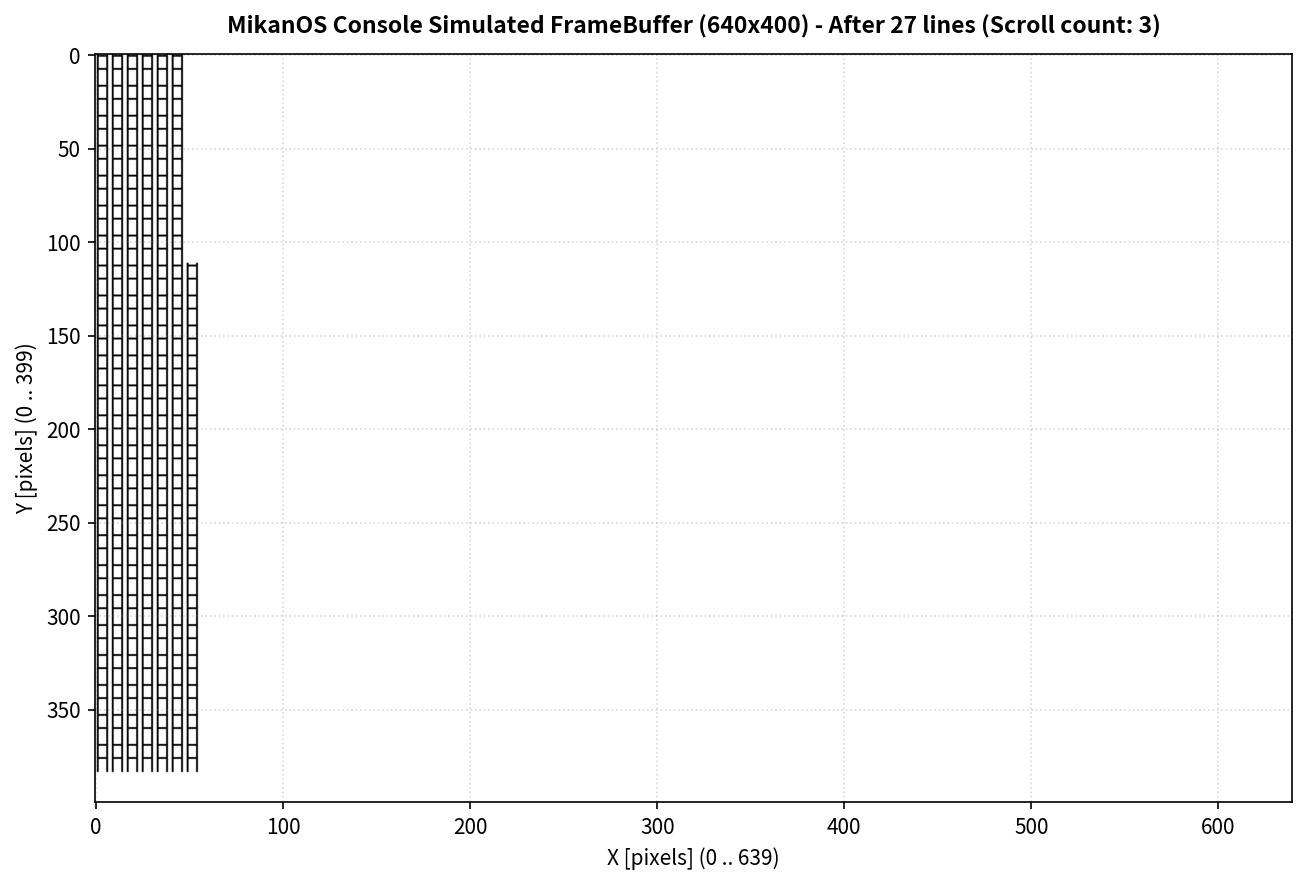

In [6]:
# シミュレートされた GOP VRAM フレームバッファの可視化
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6), dpi=150)
plt.imshow(console.framebuffer)
plt.title(f"MikanOS Console Simulated FrameBuffer (640x400) - After 27 lines (Scroll count: {console.scroll_count})",
          fontsize=11, fontweight="bold", pad=10)
plt.xlabel("X [pixels] (0 .. 639)")
plt.ylabel("Y [pixels] (0 .. 399)")
plt.grid(color="gray", linestyle=":", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. まとめと次節への架け橋

### 本節で達成した重要成果
1. **画面描画の完全カプセル化**:
   - `Console` クラスの導入により、呼び出し側（カーネル）はピクセル座標を意識することなく、文字列を渡すだけで自動前進・改行・スクロール表示が可能になりました。
2. **80列×25行 テキストバッファ (`char buffer_[25][81]`) の二重管理**:
   - MMIO（VRAM）の読み戻しペナルティを回避し、メモリ上で高速な行シフト（`memcpy`）と画面再描画（`WriteString`）を実現しました。
3. **境界保護と POSIX 準拠スタブ**:
   - 行末 80文字制限によるバッファオーバーフロー防止、および `sbrk()` の `errno = ENOMEM` 改善により、堅牢な基盤を確立しました。

---

### 次節予告: 5.6節 `printk()` の実装へ！
コンソールクラスが完成したことで、画面出力の土台は整いました。
しかし、まだ `char buf[128]; sprintf(buf, ...); console.PutString(buf);` と毎回一時バッファを用意して2段階で呼び出さなければなりません。

次節（5.6節 `osbook_day05f`）では、C標準ライブラリの `printf` に相当する、**カーネル用書式付き出力関数 `printk()`** を実装します！
`va_list` と `vsnprintf` を駆使し、一行で `printk("line %d\n", i);` と直接コンソールへ出力できる究極の利便性を手に入れます！